<a href="https://colab.research.google.com/github/speediedan/finetuning-scheduler/blob/main/src/fts_examples/notebooks/publish/tunable_views/lora_placement.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" />
</a>

# Where Should LoRA Go? Probing *LoRA Without Regret* with Addresses

[LoRA Without Regret](https://thinkingmachines.ai/blog/lora/) (Schulman and Thinking Machines Lab, September 2025)
reports that where LoRA adapters sit matters more than their parameter count: on small and medium supervised datasets,
LoRA on the MLP layers matches full fine-tuning, adding attention adapters on top of them gains nothing, and LoRA on the
attention layers alone falls behind, even when given as many parameters as the MLP adapters.

This notebook probes that claim at small scale, and along the way shows how Fine-Tuning Scheduler's experimental
[tunable views and addresses](https://finetuning-scheduler.readthedocs.io/en/latest/pytorch/tunable_views.html) are
used in an experiment:

1. **a view from the model's component map**: Qwen3-0.6B gets LoRA adapters on all seven of its projections, and
   venngram's `MappedView` gives the adapters a role and every tensor its layer and architecture-neutral component
   (`attn.q`, `mlp.out`, `ln2`, ...), read from the component map for its architecture;
2. **the experimental conditions are addresses**: attention-only, MLP-only and all-layer LoRA are three one-line
   schedules (`role:adapter & component:attn.*`, ...) over that same model, so nothing but the address differs between
   them. Untrained adapters are exact no-ops (their `lora_B` starts at zero);
3. **conditions beyond placement**: MLP adapters plus the model's own normalization weights (the `base` role, selected
   by component), and one only a scheduler can express: MLP adapters first, then the attention adapters added
   halfway.

It is a probe, not a replication: a 0.6B model, a slice of GSM8K, a few hundred steps, one seed. Treat the result as
a hypothesis check, and scale it up (more steps, seeds, a learning-rate sweep) before drawing conclusions.

For one model and a schedule you write by hand, parameter names and regexes are usually all you need, and they stay
fully supported. Views and addresses earn their keep when conditions are compositions over a model's structure, as
here, or when an experiment should be defined once and run on several models: its conditions name roles and
components rather than one model's parameters, so the definition is largely model independent, and a person, a sweep
or an agent can orchestrate it across models without per-model edits
([why Fine-Tuning Scheduler is evolving](https://finetuning-scheduler.readthedocs.io/en/latest/evolution.html)).
The companion notebook, [Addressing Across Architectures](cross_architecture_addresses.ipynb), compiles this
notebook's conditions, unchanged, on four model families side by side, without training.

## Setup

The parameters below set the run's size (the docs render uses them as given; the tests shorten them).

In [2]:
MODEL_ID = "Qwen/Qwen3-0.6B"
RANK = 16
ALPHA = 32
LR = 2e-4  # LoRA's best rate is about 10x full fine-tuning's (LoRA Without Regret); 2e-5 is a typical full rate here
MAX_STEPS = 300
EVAL_EVERY = 25
BATCH_SIZE = 8
SEQ_LEN = 256
N_TRAIN = 2400
N_EVAL = 256
SEED = 42

In [3]:
import copy
import random
import warnings

import datasets
import matplotlib.pyplot as plt
import torch
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

from finetuning_scheduler import TuningScheduler
from finetuning_scheduler.core.compile import compile_schedule
from finetuning_scheduler.testing import TunableViewConformance
from venngram.maps import MappedView, PEFT_LORA_RULES

from fts_examples.tunable_views.lora import add_lora

warnings.filterwarnings("ignore", message=".*addresses.*experimental")  # said once per process; we know
datasets.disable_progress_bars()
transformers.utils.logging.disable_progress_bar()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.bfloat16 if device.type == "cuda" else torch.float32
print(f"device: {device}, dtype: {dtype}")

device: cuda, dtype: torch.bfloat16


## The Data

Grade-school math word problems with worked answers ([GSM8K](https://huggingface.co/datasets/openai/gsm8k)), as
`Question: ... Answer: ...` text. The loss is next-token cross-entropy over the whole sequence, and the evaluation set
is a fixed slice of the test split.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
gsm8k = load_dataset("openai/gsm8k", "main")


def encode(split, n):
    texts = [f"Question: {r['question']}\nAnswer: {r['answer']}{tokenizer.eos_token}" for r in gsm8k[split].select(range(n))]
    return tokenizer(texts, truncation=True, max_length=SEQ_LEN, padding="max_length", return_tensors="pt")


train_data, eval_data = encode("train", N_TRAIN), encode("test", N_EVAL)


def batches(data, size, shuffle_seed=None):
    order = list(range(data["input_ids"].shape[0]))
    if shuffle_seed is not None:
        random.Random(shuffle_seed).shuffle(order)
    for i in range(0, len(order) - size + 1, size):
        idx = order[i:i + size]
        ids, mask = data["input_ids"][idx].to(device), data["attention_mask"][idx].to(device)
        yield ids, mask, ids.masked_fill(mask == 0, -100)


print(f"{train_data['input_ids'].shape[0]} training and {eval_data['input_ids'].shape[0]} evaluation sequences of {SEQ_LEN} tokens")

2400 training and 256 evaluation sequences of 256 tokens


## The Model and Its View

The base model is loaded once and every condition starts from a copy of it, so every condition starts from identical
adapters too. `add_lora` wraps each target projection in a `LoRALinear`: the frozen base layer plus
$\frac{\alpha}{r} B A x$, with $B$ initialized to zero.

`MappedView` (from [venngram](https://github.com/speediedan/venngram), the package that holds the tunable view
protocol and the address grammar) builds a view from the model and its architecture's component map. It keeps the model's own parameter names, so names
and regexes still work through it, and adds two things a schedule can address:

- **roles**: `PEFT_LORA_RULES` names PEFT's adapter tensors (`lora_A`, `lora_B`, ...), which `LoRALinear` shares, so
  every LoRA tensor is an `adapter`. Every other tensor is `base`: the model's own weights, frozen unless a schedule
  selects them (`role:base & ...`);
- **layers and components**: each tensor's block and its architecture-neutral component, from venngram's bundled
  component map for `Qwen3ForCausalLM`. A LoRA tensor takes the component of the projection it adapts, so
  `role:adapter & component:mlp.*` is the MLP adapters on any mapped architecture, whatever its modules are called.

`MappedView` finds the map by the model's architecture (here `Qwen3ForCausalLM`), among the maps venngram ships and
any registered in the process. How maps are found is experimental and still growing: a shared registry of maps is
planned.

In [5]:
torch.manual_seed(SEED)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device)
TARGETS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")
add_lora(base, TARGETS, r=RANK, alpha=ALPHA)
base.requires_grad_(False)

view = MappedView(base, role_rules=PEFT_LORA_RULES)
structure = view.structure()
for name in ("model.layers.27.self_attn.q_proj.lora_A.weight", "model.layers.27.mlp.down_proj.base.weight",
             "model.layers.0.post_attention_layernorm.weight", "model.embed_tokens.weight"):
    print(f"{name:<52} role={view.roles().get(name, 'base'):<8} {structure.locate(name)}")

model.layers.27.self_attn.q_proj.lora_A.weight       role=adapter  Location(stack=None, layer=27, component='attn.q')
model.layers.27.mlp.down_proj.base.weight            role=base     Location(stack=None, layer=27, component='mlp.out')
model.layers.0.post_attention_layernorm.weight       role=base     Location(stack=None, layer=0, component='ln2')
model.embed_tokens.weight                            role=base     Location(stack=None, layer=None, component='embed')


## Checking the View

`TunableViewConformance` runs every case of the protocol and every case Fine-Tuning Scheduler relies on: compiling a
schedule, thawing, an optimizer step and the refusals. It takes a factory, because the cases change the model.

In [6]:
report = TunableViewConformance(lambda: MappedView(copy.deepcopy(base), role_rules=PEFT_LORA_RULES)).run()
print("conformance:", "ok" if report.ok else report.failures)

conformance: ok


## The Conditions Are Addresses

Each condition is a schedule. The first four have one phase, so they only select what trains. "MLP + norms" adds the
model's own block normalization weights (`ln1`, `ln2`) to the MLP adapters: they are `base` tensors, thawed and trained
in full beside the adapters, a common companion to LoRA. The last thaws the MLP adapters first and adds the attention
adapters halfway through.

| condition | phase 0 | phase 1 (from step `MAX_STEPS // 2`) |
| --- | --- | --- |
| attention only | `role:adapter & component:attn.*` | |
| MLP only | `role:adapter & component:mlp.*` | |
| all layers | `role:adapter` | |
| MLP + norms | `role:adapter & component:mlp.*`, `role:base & (component:ln1 \| component:ln2)` | |
| MLP, then attention | `role:adapter & component:mlp.*` | `role:adapter & component:attn.*` |

As regexes these would be `.*self_attn\.[qkvo]_proj\.lora_[AB].*` and the like: fine for this model, but tied to its
module names. The addresses mean the same tensors on any model whose view reports these components, which
[Addressing Across Architectures](cross_architecture_addresses.ipynb) shows on four model families.

In [7]:
CONDITIONS = {
    "attention only": {0: {"params": ["role:adapter & component:attn.*"]}},
    "MLP only": {0: {"params": ["role:adapter & component:mlp.*"]}},
    "all layers": {0: {"params": ["role:adapter"]}},
    "MLP + norms": {0: {"params": ["role:adapter & component:mlp.*", "role:base & (component:ln1 | component:ln2)"]}},
    "MLP, then attention": {0: {"params": ["role:adapter & component:mlp.*"], "max_transition_step": MAX_STEPS // 2},
                            1: {"params": ["role:adapter & component:attn.*"]}},
}
params = dict(base.named_parameters())
trainable = {}
for name, schedule in CONDITIONS.items():
    compiled = compile_schedule(schedule, view)
    names = [n for p in compiled.phases for n in p.physical]
    trainable[name] = sum(params[n].numel() for n in names)
    print(f"{name:<20} {len(names):>4} tensors, {trainable[name] / 1e6:6.2f}M trainable parameters")

attention only        224 tensors,   4.59M trainable parameters
MLP only              168 tensors,   5.51M trainable parameters
all layers            392 tensors,  10.09M trainable parameters
MLP + norms           224 tensors,   5.56M trainable parameters
MLP, then attention   392 tensors,  10.09M trainable parameters


At equal rank, the attention-only and MLP-only conditions train nearly the same number of parameters on this model,
so their comparison is close to the matched-parameter comparison the paper emphasizes.

## Training

The loop is plain PyTorch. `TuningScheduler` thaws each phase's tensors, builds the optimizer over them, and adds the
next phase's tensors to it at the transition, which `step_end()` checks after each optimizer step.

In [8]:
@torch.no_grad()
def evaluate(model):
    model.eval()
    losses = [model(input_ids=ids, attention_mask=mask, labels=labels).loss.item()
              for ids, mask, labels in batches(eval_data, BATCH_SIZE)]
    model.train()
    return sum(losses) / len(losses)


def train(schedule):
    model = copy.deepcopy(base)
    fts = TuningScheduler(model, schedule, view=MappedView(model, role_rules=PEFT_LORA_RULES),
                          optimizer=lambda groups: torch.optim.AdamW(groups, lr=LR, weight_decay=0.0), base_max_lr=LR)
    fts.setup()
    curve, step = [(0, evaluate(model))], 0
    for _ in fts.epochs(max_epochs=1):
        while step < MAX_STEPS:
            for ids, mask, labels in batches(train_data, BATCH_SIZE, shuffle_seed=SEED + step):
                model(input_ids=ids, attention_mask=mask, labels=labels).loss.backward()
                fts.optimizer.step()
                fts.optimizer.zero_grad()
                fts.step_end()
                step += 1
                if step % EVAL_EVERY == 0 or step == MAX_STEPS:
                    curve.append((step, evaluate(model)))
                if step == MAX_STEPS:
                    break
    del model, fts
    torch.cuda.empty_cache() if device.type == "cuda" else None
    return curve


results = {}
for name, schedule in CONDITIONS.items():
    results[name] = train(schedule)
    print(f"{name:<20} eval loss {results[name][0][1]:.4f} -> {results[name][-1][1]:.4f}")

attention only       eval loss 1.7620 -> 1.0432


MLP only             eval loss 1.7620 -> 1.0322


all layers           eval loss 1.7620 -> 1.0276


MLP + norms          eval loss 1.7620 -> 1.0332


MLP, then attention  eval loss 1.7620 -> 1.0303


## Results

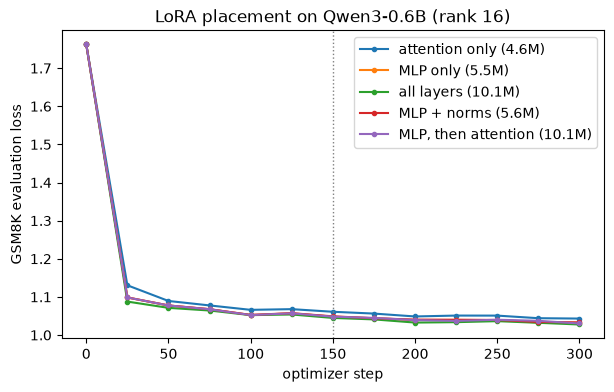

all layers           final eval loss 1.0276 (+0.0000 vs best)
MLP, then attention  final eval loss 1.0303 (+0.0026 vs best)
MLP only             final eval loss 1.0322 (+0.0045 vs best)
MLP + norms          final eval loss 1.0332 (+0.0055 vs best)
attention only       final eval loss 1.0432 (+0.0156 vs best)


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, curve in results.items():
    steps, losses = zip(*curve)
    ax.plot(steps, losses, marker="o", markersize=3, label=f"{name} ({trainable[name] / 1e6:.1f}M)")
ax.axvline(MAX_STEPS // 2, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("optimizer step")
ax.set_ylabel("GSM8K evaluation loss")
ax.set_title(f"LoRA placement on {MODEL_ID.split('/')[-1]} (rank {RANK})")
ax.legend()
plt.show()

best = min(results, key=lambda n: results[n][-1][1])
for name, curve in sorted(results.items(), key=lambda kv: kv[1][-1][1]):
    print(f"{name:<20} final eval loss {curve[-1][1]:.4f} ({curve[-1][1] - results[best][-1][1]:+.4f} vs best)")

## What This Shows

In the docs render of this notebook (300 steps, one seed), the four placement conditions finish in the order the
paper predicts at the ends, with a closer call in the middle:

- **Attention-only LoRA lags.** It finishes clearly behind the others, by about 0.016 in evaluation loss against the
  best condition, while training only about 17% fewer parameters than MLP-only LoRA. That is the paper's central
  placement result, and the near-matched parameter counts make it hard to explain by capacity alone.
- **MLP-only LoRA comes close to all-layer LoRA.** Its gap to all-layer LoRA is about a third of attention-only's,
  with roughly half the trainable parameters. The paper finds no benefit from adding attention adapters to MLP ones;
  here a small one remains, which one seed and 300 steps cannot separate from noise.
- **Training the norms adds nothing here.** MLP + norms trains the model's own block normalization weights (about
  57K `base` parameters) beside the MLP adapters, and finishes level with MLP-only LoRA (0.001 behind it, well inside
  what one seed can resolve). Selecting them took one more address, `role:base & (component:ln1 | component:ln2)`,
  with no change to the model or the view.
- **Phasing costs little.** Thawing the MLP adapters first and adding the attention adapters halfway finishes between
  MLP-only and all-layer LoRA, as the schedule would suggest: one more composition over the same view, written as two
  addresses.

The gaps are small at this scale, and a single seed cannot show they are significant. The next steps are the ones a
real study would take: several seeds, a learning-rate sweep per condition (the paper finds the optimal rate is nearly
independent of rank but scales with the method), longer runs, and a matched-parameter control (raise the
attention-only rank until the counts match). Each is a change to the parameters cell or to one address, not to the
model or the view.

## Doing This for Your Own Model

The steps are the same for any model: give it a view, decide which roles and components a schedule needs to name,
check the view with the conformance suite, then write the conditions as addresses.

- If venngram has a component map for the architecture, `MappedView(model, role_rules=...)` is the view, as here.
  If not, use Fine-Tuning Scheduler's `tunable-view-generator` agent skill: it drafts the map (a short YAML document
  naming each component's module) from the model's module tree, verifies it against the architecture with
  `venngram.maps.verify`, and registers it. When only roles or layers are wanted, `CanonicalView(model, roles=...)`
  is enough.
- [Addressing Across Architectures](cross_architecture_addresses.ipynb) checks that a set of addresses means the same thing on several model
  families before any training.
- `fts_examples/tunable_views/two_families.py` runs the same steps on two small, randomly initialized model families
  (Llama- and OPT-style) on CPU, with one address book and schedule for both, and checks the schedule against the
  equivalent regex schedule.